# SCELTA DEGLI ESEMPI PER IL TEST

In questo notebook prepariamo i tre dataset per gli esperimenti sui VLM:

1. **KANDY BONGARD**: andiamo a prendere i dati già forniti e decomporli anche in singole immagini.
2. **Bongard-RWR+**: sottoinsieme di RWR+, disponibile in formato immagini singole e Bongard.
3. **KANDY + RWR+**: sottoinsieme combinato contenente esclusivamente task semanticamente equivalenti nei due datasets, disponibile in formato immagini singole e Bongard.

I dataset originali non vengono modificati. I dataset sperimentali vengono costruiti in `data/processed/`.

La selezione dei task e la corrispondenza tra concetti vengono documentate nei rispettivi file di metadati.

## Importazione Librerie e Percorsi

In [14]:
from pathlib import Path
import json
import shutil
import random
import pandas as pd
from PIL import Image, ImageOps

#percorso del progetto
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").is_dir() and (PROJECT_ROOT.parent / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

#dataset originali
DATA_DIR = PROJECT_ROOT / "data"
KANDY_EASY_DIR = DATA_DIR / "easy"
KANDY_HARD_DIR = DATA_DIR / "hard"
KANDY_BONGARD_DIR = DATA_DIR / "kandy-bongard"
RWR_PLUS_DIR = DATA_DIR / "bongard-rwr-plus"

#cartella dei dataset sperimentali
PROCESSED_DIR = DATA_DIR / "processed"

#layout bongard comune a kandy e rwr+
TILE_SIZE = 250


def create_bongard_grid(left_images, right_images, output_dir):
    #creiamo una griglia 4x3 con due colonne per lato
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    canvas = Image.new("RGB", (1024, 768), "black")
    x_positions = [2, 257, 517, 772]
    y_positions = [0, 259, 518]

    #prepariamo sei slot per ciascun lato
    left_slots = list(left_images[:6]) + [None] * max(0, 6 - len(left_images))
    right_slots = list(right_images[:6]) + [None] * max(0, 6 - len(right_images))

    #inseriamo le immagini e lasciamo bianchi gli slot vuoti
    for side_images, columns in [(left_slots, [0, 1]), (right_slots, [2, 3])]:
        for i, image_path in enumerate(side_images):
            row, col = divmod(i, 2)
            x = x_positions[columns[col]]
            y = y_positions[row]
            tile = Image.new("RGB", (TILE_SIZE, TILE_SIZE), "white")

            if image_path is not None:
                with Image.open(image_path) as image:
                    image = ImageOps.contain(
                        image.convert("RGB"),
                        (TILE_SIZE, TILE_SIZE),
                        method=Image.Resampling.LANCZOS
                    )
                    tile.paste(
                        image,
                        ((TILE_SIZE - image.width) // 2,
                         (TILE_SIZE - image.height) // 2)
                    )

            canvas.paste(tile, (x, y))

    #salviamo la griglia completa e i due lati
    whole_path = output_dir / "whole.png"
    left_path = output_dir / "left.png"
    right_path = output_dir / "right.png"

    canvas.save(whole_path)
    canvas.crop((0, 0, 512, 768)).save(left_path)
    canvas.crop((512, 0, 1024, 768)).save(right_path)

    return whole_path, left_path, right_path


#verifica dei percorsi
source_dirs = {
    "KANDY-Easy": KANDY_EASY_DIR,
    "KANDY-Hard": KANDY_HARD_DIR,
    "KANDY-Bongard": KANDY_BONGARD_DIR,
    "Bongard-RWR+": RWR_PLUS_DIR
}

for name, path in source_dirs.items():
    print(f"{name}: {'OK' if path.exists() else 'NON TROVATO'} - {path}")

print(f"\nOutput: {PROCESSED_DIR}")

KANDY-Easy: OK - /home/cosimo/progetti/tesi/data/easy
KANDY-Hard: OK - /home/cosimo/progetti/tesi/data/hard
KANDY-Bongard: OK - /home/cosimo/progetti/tesi/data/kandy-bongard
Bongard-RWR+: OK - /home/cosimo/progetti/tesi/data/bongard-rwr-plus

Output: /home/cosimo/progetti/tesi/data/processed


## Analisi delle Strutture

In [15]:
#struttura kandy easy/hard
for name, root in [("KANDY-Easy", KANDY_EASY_DIR), ("KANDY-Hard", KANDY_HARD_DIR)]:
    print(f"\n{name}")
    for csv_path in sorted(root.rglob("annotations.csv")):
        df = pd.read_csv(csv_path)
        print(f"{csv_path.relative_to(root)}: {len(df)} righe")
        print(f"Colonne: {list(df.columns)}")

#struttura kandy-bongard
print("\nKANDY-Bongard")
for view_dir in sorted(KANDY_BONGARD_DIR.iterdir()):
    if view_dir.is_dir():
        print(f"\n{view_dir.name}")
        for subdir in sorted(view_dir.iterdir()):
            if subdir.is_dir():
                print(f"  {subdir.name}: {len(list(subdir.iterdir()))} elementi")

#struttura rwr+
print("\nBongard-RWR+")
for subdir in sorted(RWR_PLUS_DIR.iterdir()):
    if subdir.is_dir():
        print(f"{subdir.name}: {len(list(subdir.iterdir()))} elementi")

#metadati rwr+
rwr_json_path = RWR_PLUS_DIR / "dataset.json"

with open(rwr_json_path, "r") as f:
    rwr_data = json.load(f)

rwr_records = rwr_data["problems"] if isinstance(rwr_data, dict) else rwr_data

print(f"\nProblemi RWR+: {len(rwr_records)}")
print(f"Campi disponibili: {list(rwr_records[0].keys())}")
print(f"Immagini di contesto per lato: {len(rwr_records[0]['left_images']) - 1}")
print(f"Immagini totali per lato: {len(rwr_records[0]['left_images'])}")


KANDY-Easy
samples/sets/test/annotations.csv: 500 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']
samples/sets/train/annotations.csv: 1000 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']
samples/sets/val/annotations.csv: 500 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']
samples/shuffled_curriculum/test/annotations.csv: 500 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']
samples/shuffled_curriculum/train/annotations.csv: 1000 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']
samples/shuffled_curriculum/val/annotations.csv: 500 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']

KANDY-Hard
samples/sets/test/annotations.csv: 255 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']
samples/sets/train/annotations.csv: 1290 righe
Colonne: ['filename', 'task_id', 'label', 'supervised', 'symbol']
samples/sets/val/annotations.csv: 255 r

## Decomposizione KANDY-Bongard

Per questo dataset quello che andiamo a fare è semplicemente rislari tramite le annotazioni ai nomi dei task utilizzati e, siccome per costruirli sono stati scelti i primi 6 esempi positivi e negativi per task andiamo a prendere quelli. Per uniformare i test, quello che andremo a fare dopo la "decomposizione" sarà ri-arrangiarli in una griglia simile a quella di RWR+; anche in KANDY era presenta una modalità a griglia ma anche questa era diversa quindi ho preferito uniformare le due rappresentazioni.

In [16]:
#definiamo le cartelle di output
KANDY_OUTPUT_DIR = PROCESSED_DIR / "dataset_1_kandy"
KANDY_SINGLE_DIR = KANDY_OUTPUT_DIR / "single"
KANDY_BONGARD_OUTPUT_DIR = KANDY_OUTPUT_DIR / "bongard"

#ricreiamo il dataset kandy
if KANDY_OUTPUT_DIR.exists():
    shutil.rmtree(KANDY_OUTPUT_DIR)

KANDY_SINGLE_DIR.mkdir(parents=True, exist_ok=True)
KANDY_BONGARD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

#decomponiamo i 38 task usando gli esempi del test set
kandy_records = []
task_counts = {"easy": 20, "hard": 18}

for level, n_tasks in task_counts.items():

    test_dir = DATA_DIR / level / "samples" / "sets" / "test"
    annotations = pd.read_csv(test_dir / "annotations.csv")

    for task_id in range(n_tasks):

        problem_id = f"{level}-{task_id}"
        task = annotations[annotations["task_id"] == task_id]
        problem_single_dir = KANDY_SINGLE_DIR / problem_id
        problem_single_dir.mkdir(parents=True, exist_ok=True)

        #selezioniamo fino a sei esempi per lato
        positive = task[task["label"] == 1].head(6)
        negative = task[task["label"] == 0].head(6)

        #copiamo le immagini singole
        side_paths = {}

        for side, samples in [("positive", positive), ("negative", negative)]:
            side_dir = problem_single_dir / side
            side_dir.mkdir(parents=True, exist_ok=True)
            copied = []

            for i, (_, row) in enumerate(samples.iterrows(), start=1):
                source = test_dir / row["filename"]
                destination = side_dir / f"{side}_{i:02d}{source.suffix}"
                shutil.copy2(source, destination)
                copied.append(destination)

            side_paths[side] = copied

        #ricostruiamo il bongard senza usare il fondale foundalis originale
        problem_bongard_dir = KANDY_BONGARD_OUTPUT_DIR / problem_id
        whole, left, right = create_bongard_grid(
            side_paths["positive"],
            side_paths["negative"],
            problem_bongard_dir
        )

        #registriamo i metadati
        kandy_records.append({
            "problem_id": problem_id,
            "level": level,
            "task_id": task_id,
            "positive_images": json.dumps([
                str(p.relative_to(KANDY_OUTPUT_DIR)) for p in side_paths["positive"]
            ]),
            "negative_images": json.dumps([
                str(p.relative_to(KANDY_OUTPUT_DIR)) for p in side_paths["negative"]
            ]),
            "n_positive": len(side_paths["positive"]),
            "n_negative": len(side_paths["negative"]),
            "positive_blank_slots": 6 - len(side_paths["positive"]),
            "negative_blank_slots": 6 - len(side_paths["negative"]),
            "whole_image": str(whole.relative_to(KANDY_OUTPUT_DIR)),
            "left_image": str(left.relative_to(KANDY_OUTPUT_DIR)),
            "right_image": str(right.relative_to(KANDY_OUTPUT_DIR))
        })

        print(f"{problem_id}: {len(positive)} positivi, {len(negative)} negativi")

#salviamo il manifest
kandy_manifest = pd.DataFrame(kandy_records)
kandy_manifest.to_csv(KANDY_OUTPUT_DIR / "manifest.csv", index=False)

print("\nProblemi elaborati:", len(kandy_manifest))
print("Immagini positive:", kandy_manifest["n_positive"].sum())
print("Immagini negative:", kandy_manifest["n_negative"].sum())
print("Percorso:", KANDY_OUTPUT_DIR)

easy-0: 6 positivi, 6 negativi
easy-1: 6 positivi, 6 negativi
easy-2: 6 positivi, 6 negativi
easy-3: 6 positivi, 6 negativi
easy-4: 6 positivi, 6 negativi
easy-5: 6 positivi, 6 negativi
easy-6: 6 positivi, 6 negativi
easy-7: 6 positivi, 6 negativi
easy-8: 5 positivi, 6 negativi
easy-9: 6 positivi, 6 negativi
easy-10: 6 positivi, 6 negativi
easy-11: 6 positivi, 6 negativi
easy-12: 6 positivi, 6 negativi
easy-13: 6 positivi, 6 negativi
easy-14: 6 positivi, 6 negativi
easy-15: 6 positivi, 6 negativi
easy-16: 6 positivi, 6 negativi
easy-17: 6 positivi, 6 negativi
easy-18: 6 positivi, 6 negativi
easy-19: 3 positivi, 6 negativi
hard-0: 4 positivi, 6 negativi
hard-1: 6 positivi, 4 negativi
hard-2: 3 positivi, 6 negativi
hard-3: 4 positivi, 6 negativi
hard-4: 6 positivi, 6 negativi
hard-5: 6 positivi, 6 negativi
hard-6: 6 positivi, 6 negativi
hard-7: 6 positivi, 6 negativi
hard-8: 6 positivi, 6 negativi
hard-9: 6 positivi, 2 negativi
hard-10: 6 positivi, 4 negativi
hard-11: 4 positivi, 6 negat

## Sottoset RWR+

Qui quello che andiamo a fare è invece prendere le stesse proporzioni di esempi dei task di KANDY, quindi uniformiamo andando a simulare una mancanza di esempi, e andare a selezionare i task randomicamente, assicurandoci però che:

1. non si scelga più volte lo stesso task
2. si scelgano task provenienti da categorie diverse

In [17]:
import random

SEED = 42
random.seed(SEED)

#quantità ricavate da KANDY
quota_values = [
    (6, 6), (6, 6), (6, 6), (6, 6), (6, 6),
    (6, 6), (6, 6), (6, 6), (5, 6), (6, 6),
    (6, 6), (6, 6), (6, 6), (6, 6), (6, 6),
    (6, 6), (6, 6), (6, 6), (6, 6), (3, 6),
    (4, 6), (6, 4), (3, 6), (4, 6), (6, 6),
    (6, 6), (6, 6), (6, 6), (6, 6), (6, 2),
    (6, 4), (4, 6), (2, 6), (6, 4), (6, 3),
    (5, 5), (6, 3), (4, 6)
]

profiles = pd.DataFrame(
    quota_values,
    columns=["n_positive", "n_negative"]
)

profiles.insert(
    0, "profile_id",
    [f"Q{i:02d}" for i in range(1, 39)]
)

#prepariamo i metadati RWR+
rwr_df = pd.DataFrame(rwr_records)

#calcoliamo le distribuzioni dei gruppi
group_sizes = rwr_df.groupby("concept_group").size().sort_index()
exact_targets = group_sizes / len(rwr_df) * len(profiles)

group_targets = exact_targets.apply(int)
remaining = len(profiles) - int(group_targets.sum())

remainders = (exact_targets - group_targets).sort_values(ascending=False)

for group in remainders.index[:remaining]:
    group_targets.loc[group] += 1

#selezioniamo coppie concettuali distinte
pair_columns = ["concept_group", "left_concept", "right_concept"]
available_pairs = rwr_df[pair_columns].drop_duplicates()

selected_rows = []
counter = 0

for group, n in group_targets.items():

    group_pairs = available_pairs[
        available_pairs["concept_group"] == group
    ]

    if len(group_pairs) < n:
        raise ValueError(f"Coppie concettuali insufficienti per {group}")

    chosen_pairs = group_pairs.sample(
        n=n, random_state=SEED + counter
    )

    for _, pair in chosen_pairs.iterrows():

        candidates = rwr_df[
            (rwr_df["concept_group"] == pair["concept_group"]) &
            (rwr_df["left_concept"] == pair["left_concept"]) &
            (rwr_df["right_concept"] == pair["right_concept"])
        ]

        selected = candidates.sample(
            n=1, random_state=SEED + 1000 + counter
        ).iloc[0].to_dict()

        selected_rows.append(selected)
        counter += 1

#mescoliamo i problemi selezionati
rwr_subset = pd.DataFrame(selected_rows).sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

#assegniamo i profili quantitativi
profiles = profiles.sample(
    frac=1, random_state=SEED + 1
).reset_index(drop=True)

rwr_subset["profile_id"] = profiles["profile_id"]
rwr_subset["n_positive"] = profiles["n_positive"]
rwr_subset["n_negative"] = profiles["n_negative"]

#verifichiamo la selezione
assert len(rwr_subset) == 38
assert rwr_subset["id"].nunique() == 38
assert rwr_subset[pair_columns].drop_duplicates().shape[0] == 38

print("Problemi selezionati:", len(rwr_subset))
print("Coppie concettuali distinte:", rwr_subset[pair_columns].drop_duplicates().shape[0])
print("\nDistribuzione per gruppo:")
print(rwr_subset["concept_group"].value_counts().sort_index())

print("\nImmagini di contesto previste:")
print("Lato positivo:", rwr_subset["n_positive"].sum())
print("Lato negativo:", rwr_subset["n_negative"].sum())

display(
    rwr_subset[
        ["profile_id", "id", "concept_group",
         "left_concept", "right_concept",
         "n_positive", "n_negative", "diversity"]
    ].sort_values("profile_id")
)

Problemi selezionati: 38
Coppie concettuali distinte: 38

Distribuzione per gruppo:
concept_group
Angle         3
Branching     1
Contour       3
Count         6
Position      9
Rotation      4
Shape         6
Similarity    3
Size          3
Name: count, dtype: int64

Immagini di contesto previste:
Lato positivo: 208
Lato negativo: 211


,profile_id,id,concept_group,left_concept,right_concept,n_positive,n_negative,diversity
36,Q01,88041,Position,Outline circles on one straight line,Outline circles not on one straight line,6,6,0.200
24,Q02,52004,Angle,Convex figures,Nonconvex figures,6,6,0.179
31,Q03,57023,Count,One figure,Two figures,6,6,0.211
27,Q04,62070,Branching,There are no side branches of the second order,There are side branches of the second order,6,6,0.089
37,Q05,41096,Shape,Triangles,Quadrangles,6,6,0.290
15,Q06,90090,Count,Three parts,Four parts,6,6,0.178
5,Q07,73005,Shape,Polygons,Curvilinear figures,6,6,0.157
4,Q08,52024,Shape,A circle,No circle,6,6,0.199
13,Q09,56087,Count,Four parts,Five parts,5,6,0.217
7,Q10,40011,Shape,Elongated figures,Compact figures,6,6,0.143


In [18]:
#selezioniamo le immagini di contesto
def sample_context(images, n, seed):
    indices = sorted(random.Random(seed).sample(range(len(images)), n))
    return [images[i] for i in indices]

#risolviamo i percorsi delle immagini
def resolve_rwr_path(image_ref):
    path = Path(image_ref)
    return path if path.is_absolute() else RWR_PLUS_DIR / path

rwr_selection = []

for _, row in rwr_subset.iterrows():

    left_images = row["left_images"]
    right_images = row["right_images"]

    #verifichiamo la struttura originale
    if len(left_images) != 7 or len(right_images) != 7:
        raise ValueError(f"Numero di immagini inatteso nel problema {row['id']}")

    #selezioniamo le immagini di contesto
    left_context = sample_context(
        left_images[:6], int(row["n_positive"]), SEED + int(row["id"])
    )

    right_context = sample_context(
        right_images[:6], int(row["n_negative"]), SEED + int(row["id"]) + 1
    )

    #conserviamo separatamente le immagini di test
    left_test = left_images[6]
    right_test = right_images[6]

    #prepariamo il record
    record = {
        "profile_id": row["profile_id"],
        "id": row["id"],
        "concept_group": row["concept_group"],
        "left_concept": row["left_concept"],
        "right_concept": row["right_concept"],
        "diversity": row["diversity"],
        "left_context_images": left_context,
        "right_context_images": right_context,
        "left_test_image": left_test,
        "right_test_image": right_test,
        "whole_image": row["whole_image"],
        "left_side_image": row["left_side_image"],
        "right_side_image": row["right_side_image"]
    }

    #verifichiamo che tutti i file esistano
    image_refs = (
        left_context + right_context +
        [left_test, right_test, row["whole_image"],
         row["left_side_image"], row["right_side_image"]]
    )

    missing = [
        ref for ref in image_refs
        if not resolve_rwr_path(ref).is_file()
    ]

    if missing:
        raise FileNotFoundError(
            f"Immagini mancanti nel problema {row['id']}: {missing}"
        )

    rwr_selection.append(record)

rwr_selection_df = pd.DataFrame(rwr_selection)

#verifichiamo i risultati
print("Problemi selezionati:", len(rwr_selection_df))
print("Immagini di contesto lato sinistro:",
      rwr_selection_df["left_context_images"].apply(len).sum())
print("Immagini di contesto lato destro:",
      rwr_selection_df["right_context_images"].apply(len).sum())
print("Immagini di test:",
      len(rwr_selection_df) * 2)

display(
    rwr_selection_df[
        ["profile_id", "id", "concept_group",
         "left_concept", "right_concept",
         "left_context_images", "right_context_images"]
    ]
)

Problemi selezionati: 38
Immagini di contesto lato sinistro: 208
Immagini di contesto lato destro: 211
Immagini di test: 76


,profile_id,id,concept_group,left_concept,right_concept,left_context_images,right_context_images
0,Q20,30022,Similarity,Areas of figures approximately equal,Areas of figures differ greatly,"[images/3019.jpg, images/242.jpg, images/3020....","[images/249.jpg, images/250.jpg, images/251.jp..."
1,Q14,91034,Size,A large hole,A small hole,"[images/1014.jpg, images/3054.jpg, images/3662...","[images/1017.jpg, images/1018.jpg, images/370...."
2,Q25,69014,Contour,Large total line length,Small total line length,"[images/878.jpg, images/176.jpg, images/3618.j...","[images/881.jpg, images/180.jpg, images/2479.j..."
3,Q30,20047,Position,Triangle inside of the circle,Circle inside of the triangle,"[images/2853.jpg, images/486.jpg, images/2854....","[images/495.jpg, images/496.jpg]"
4,Q08,52024,Shape,A circle,No circle,"[images/3447.jpg, images/273.jpg, images/3445....","[images/1445.jpg, images/1442.jpg, images/1444..."
5,Q07,73005,Shape,Polygons,Curvilinear figures,"[images/3594.jpg, images/500.jpg, images/80.jp...","[images/1630.jpg, images/1629.jpg, images/1631..."
6,Q34,57063,Contour,Shading thicker on the right side,Shading thicker on the left side,"[images/3341.jpg, images/2896.jpg, images/3523...","[images/2419.jpg, images/629.jpg, images/1947...."
7,Q10,40011,Shape,Elongated figures,Compact figures,"[images/3212.jpg, images/3213.jpg, images/3214...","[images/152.jpg, images/154.jpg, images/150.jp..."
8,Q21,28052,Rotation,Arrows pointing in different directions,Arrows pointing in the same direction,"[images/2868.jpg, images/1138.jpg, images/540....","[images/2535.jpg, images/2533.jpg, images/2532..."
9,Q36,74030,Position,A line with a self-crossing,A line without a self-crossing,"[images/3810.jpg, images/3812.jpg, images/3036...","[images/1455.jpg, images/1452.jpg, images/976...."


In [24]:
import shutil

#definiamo le cartelle
RWR_OUTPUT_DIR = PROCESSED_DIR / "dataset_2_rwr_plus"
SINGLE_DIR = RWR_OUTPUT_DIR / "single"
BONGARD_DIR = RWR_OUTPUT_DIR / "bongard_original"

#copiamo le immagini selezionate
manifest_records = []

for _, row in rwr_selection_df.iterrows():

    problem = row["profile_id"]
    problem_single_dir = SINGLE_DIR / problem
    problem_bongard_dir = BONGARD_DIR / problem

    #copiamo contesto e test dei due lati
    copied_paths = {}

    for side in ["left", "right"]:

        side_dir = problem_single_dir / side
        side_dir.mkdir(parents=True, exist_ok=True)

        context = row[f"{side}_context_images"]
        copied_context = []

        for i, ref in enumerate(context, start=1):
            source = resolve_rwr_path(ref)
            destination = side_dir / f"context_{i:02d}{source.suffix}"
            shutil.copy2(source, destination)
            copied_context.append(str(destination.relative_to(RWR_OUTPUT_DIR)))

        test_ref = row[f"{side}_test_image"]
        source = resolve_rwr_path(test_ref)
        destination = side_dir / f"test{source.suffix}"
        shutil.copy2(source, destination)

        copied_paths[f"{side}_context"] = json.dumps(copied_context)
        copied_paths[f"{side}_test"] = str(destination.relative_to(RWR_OUTPUT_DIR))

    #copiamo le immagini bongard originali
    problem_bongard_dir.mkdir(parents=True, exist_ok=True)
    source_bongard_dir = problem_bongard_dir / "source"
    source_bongard_dir.mkdir(parents=True, exist_ok=True)

    for key, filename in [
        ("whole_image", "whole"),
        ("left_side_image", "left"),
        ("right_side_image", "right")
    ]:
        source = resolve_rwr_path(row[key])
        destination = source_bongard_dir / f"{filename}{source.suffix}"
        shutil.copy2(source, destination)

    #ricostruiamo la griglia rwr+ usando lo stesso layout di kandy
    left_context_paths = [
        RWR_OUTPUT_DIR / path
        for path in json.loads(copied_paths["left_context"])
    ]
    right_context_paths = [
        RWR_OUTPUT_DIR / path
        for path in json.loads(copied_paths["right_context"])
    ]

    reconstructed_dir = problem_bongard_dir / "reconstructed"
    whole, left, right = create_bongard_grid(
        left_context_paths,
        right_context_paths,
        reconstructed_dir
    )

    copied_paths["whole_image"] = str(whole.relative_to(RWR_OUTPUT_DIR))
    copied_paths["left_side_image"] = str(left.relative_to(RWR_OUTPUT_DIR))
    copied_paths["right_side_image"] = str(right.relative_to(RWR_OUTPUT_DIR))

    #registriamo i metadati
    manifest_records.append({
        "profile_id": problem,
        "id": row["id"],
        "concept_group": row["concept_group"],
        "left_concept": row["left_concept"],
        "right_concept": row["right_concept"],
        "n_left": len(row["left_context_images"]),
        "n_right": len(row["right_context_images"]),
        "diversity": row["diversity"],
        **copied_paths
    })

#salviamo il manifest
rwr_manifest = pd.DataFrame(manifest_records)
rwr_manifest.to_csv(RWR_OUTPUT_DIR / "manifest.csv", index=False)

print("Problemi esportati:", len(rwr_manifest))
print("Immagini singole:", sum(rwr_manifest["n_left"] + rwr_manifest["n_right"]) + 76)
print("Percorso:", RWR_OUTPUT_DIR)

Problemi esportati: 38
Immagini singole: 495
Percorso: /home/cosimo/progetti/tesi/data/processed/dataset_2_rwr_plus


## Dataset di Intersezione tra KANDY e RWR +

Qui quello che andiamo a fare è annotare quelle che sono le possibili intersezioni tra i due datasets e andare a costruirne un terzo ibrido. Ricostruiremo così i fondali bongard unendo sia esempi astratti come quelli di KANDY sia esempi concreti come quelli di RWR+, per i primi test e, per l'ultimo andremo a utilizzare solo esempi di KANDY per poi classificare l'esempio di RWR+.

In [ ]:
#definiamo i 38 task kandy
kandy_tasks = [
    ("easy-0", "Easy", 0, "Presenza di triangoli"),
    ("easy-1", "Easy", 1, "Presenza di quadrati"),
    ("easy-2", "Easy", 2, "Presenza di cerchi"),
    ("easy-3", "Easy", 3, "Presenza del colore rosso"),
    ("easy-4", "Easy", 4, "Presenza del colore verde"),
    ("easy-5", "Easy", 5, "Presenza del colore blu"),
    ("easy-6", "Easy", 6, "Presenza del colore ciano"),
    ("easy-7", "Easy", 7, "Presenza del colore magenta"),
    ("easy-8", "Easy", 8, "Presenza del colore giallo"),
    ("easy-9", "Easy", 9, "Triangolo rosso all'estrema destra con un altro oggetto"),
    ("easy-10", "Easy", 10, "Triangolo rosso all'estrema destra con più oggetti"),
    ("easy-11", "Easy", 11, "Triangolo rosso all'estrema destra e presenza di un cerchio"),
    ("easy-12", "Easy", 12, "Triangolo rosso all'estrema destra e presenza di un oggetto blu"),
    ("easy-13", "Easy", 13, "Triangolo e quadrato dello stesso colore"),
    ("easy-14", "Easy", 14, "Palindromo di tre oggetti"),
    ("easy-15", "Easy", 15, "Presenza di una casa"),
    ("easy-16", "Easy", 16, "Presenza di un'automobile"),
    ("easy-17", "Easy", 17, "Presenza di una torre"),
    ("easy-18", "Easy", 18, "Presenza di un carro"),
    ("easy-19", "Easy", 19, "Presenza di un semaforo"),
    ("hard-0", "Hard", 0, "Dimeri dello stesso colore"),
    ("hard-1", "Hard", 1, "Dimeri della stessa forma"),
    ("hard-2", "Hard", 2, "Trimeri dello stesso colore"),
    ("hard-3", "Hard", 3, "Trimeri della stessa forma"),
    ("hard-4", "Hard", 4, "Presenza di una casa"),
    ("hard-5", "Hard", 5, "Presenza di un'automobile"),
    ("hard-6", "Hard", 6, "Presenza di una torre"),
    ("hard-7", "Hard", 7, "Presenza di un carro"),
    ("hard-8", "Hard", 8, "Presenza di un semaforo"),
    ("hard-9", "Hard", 9, "Ogni gruppo contiene una forma condivisa"),
    ("hard-10", "Hard", 10, "Ogni gruppo contiene un colore condiviso"),
    ("hard-11", "Hard", 11, "Ogni gruppo contiene un oggetto nominato condiviso"),
    ("hard-12", "Hard", 12, "Palindromi lineari"),
    ("hard-13", "Hard", 13, "Pseudo-palindromi"),
    ("hard-14", "Hard", 14, "Pseudo-palindromi con oggetti nominati"),
    ("hard-15", "Hard", 15, "Numero dispari: stesso colore; numero pari: stessa forma"),
    ("hard-16", "Hard", 16, "Regola logica tra semaforo, automobile, casa e torre"),
    ("hard-17", "Hard", 17, "Regola logica universale applicata a una griglia")
]

kandy_catalogue = pd.DataFrame(
    kandy_tasks,
    columns=["problem_id", "dataset", "task_id", "kandy_concept"]
)

#prepariamo i 38 problemi rwr+
rwr_catalogue = rwr_subset[
    ["profile_id", "id", "concept_group", "left_concept", "right_concept"]
].copy()

#creiamo tutte le combinazioni
comparison_matrix = kandy_catalogue.merge(rwr_catalogue, how="cross")

comparison_matrix["status"] = "non_candidato"
comparison_matrix["reason"] = (
    "Nessuna corrispondenza semantica evidente nella prima ricognizione."
)

#registriamo le corrispondenze da sottoporre a revisione
candidate_reviews = {
    ("easy-0", "Q05"): ("parziale", "Triangoli contro quadrangoli in RWR+; KANDY contrappone i triangoli agli altri oggetti."),
    ("easy-0", "Q12"): ("parziale", "Entrambi coinvolgono i triangoli, ma il secondo lato di RWR+ contiene solo cerchi."),
    ("easy-2", "Q08"): ("esatta", "Presenza di un cerchio contro assenza di cerchi."),
    ("easy-2", "Q12"): ("parziale", "Il cerchio è una delle due categorie di RWR+, non una distinzione presenza/assenza."),
    ("hard-2", "Q37"): ("parziale", "Trimeri dello stesso colore contro tre o quattro elementi identici."),
    ("hard-3", "Q37"): ("parziale", "Trimeri della stessa forma contro tre o quattro elementi identici.")
}

#applichiamo le valutazioni
for (kandy_id, rwr_profile), (status, reason) in candidate_reviews.items():

    mask = (
        (comparison_matrix["problem_id"] == kandy_id) &
        (comparison_matrix["profile_id"] == rwr_profile)
    )

    if mask.sum() != 1:
        raise ValueError(f"Corrispondenza non trovata: {kandy_id} - {rwr_profile}")

    comparison_matrix.loc[mask, "status"] = status
    comparison_matrix.loc[mask, "reason"] = reason

#verifichiamo la matrice
assert len(comparison_matrix) == 38 * 38
assert (comparison_matrix["status"] == "esatta").sum() == 1

#creiamo le cartelle dei metadati
metadata_dir = PROCESSED_DIR / "metadata"
metadata_dir.mkdir(parents=True, exist_ok=True)

#salviamo la matrice completa e i soli candidati
comparison_matrix.to_csv(
    metadata_dir / "concept_comparison_kandy_rwr.csv",
    index=False
)

comparison_candidates = comparison_matrix[
    comparison_matrix["status"] != "non_candidato"
].copy()

comparison_candidates.to_csv(
    metadata_dir / "concept_comparison_candidates.csv",
    index=False
)

#riepiloghiamo i risultati
print("Combinazioni confrontate:", len(comparison_matrix))
print("\nClassificazione:")
print(comparison_matrix["status"].value_counts())

print("\nCandidati individuati:")
display(
    comparison_candidates[
        ["problem_id", "kandy_concept", "profile_id", "id",
         "left_concept", "right_concept", "status", "reason"]
    ].sort_values(["problem_id", "status", "profile_id"])
)

print("\nPercorso:", metadata_dir)

Purtroppo la sovrapposizione ha pochi elementi al suo interno, ho deciso di prendere l'unico con corrispondenza esatta, quello cioè riguardante la presenza e non presenza dei cerchi, quello riguardante i triangoli e per il terzo ho preso quello dei trimeri.

Il terzo è stato preso in quanto il task KANDY è "3 oggetti con colori uguali" (A) mentre quello di RWR+ è "3 oggetti identici" (B), siccome A $\subset$ B, allora posso utilizzare anche le immagini di RWR+ per il task di KANDY. 

In [21]:
#definiamo la composizione dei tre problemi misti
#le proporzioni cambiano tra problemi e tra i due lati
mixed_specs = [
    {
        "problem_id": "easy-0__Q05",
        "kandy_problem_id": "easy-0",
        "rwr_profile_id": "Q05",
        "rwr_problem_id": 41096,
        "left_kandy": 3, "right_kandy": 4
    },
    {
        "problem_id": "easy-2__Q08",
        "kandy_problem_id": "easy-2",
        "rwr_profile_id": "Q08",
        "rwr_problem_id": 52024,
        "left_kandy": 4, "right_kandy": 2
    },
    {
        "problem_id": "hard-2__Q37",
        "kandy_problem_id": "hard-2",
        "rwr_profile_id": "Q37",
        "rwr_problem_id": 78091,
        "left_kandy": 2, "right_kandy": 5
    }
]

#prepariamo le cartelle
OVERLAP_OUTPUT_DIR = PROCESSED_DIR / "dataset_3_overlap"
OVERLAP_SINGLE_DIR = OVERLAP_OUTPUT_DIR / "single"
OVERLAP_BONGARD_DIR = OVERLAP_OUTPUT_DIR / "bongard"

if OVERLAP_OUTPUT_DIR.exists():
    shutil.rmtree(OVERLAP_OUTPUT_DIR)

OVERLAP_SINGLE_DIR.mkdir(parents=True, exist_ok=True)
OVERLAP_BONGARD_DIR.mkdir(parents=True, exist_ok=True)

#prepariamo gli indici dei problemi
rwr_selected_by_profile = {
    row["profile_id"]: row
    for _, row in rwr_selection_df.iterrows()
}
kandy_by_problem = {
    row["problem_id"]: row
    for _, row in kandy_manifest.iterrows()
}

mixed_records = []
mixed_image_records = []

for spec_index, spec in enumerate(mixed_specs):

    problem_id = spec["problem_id"]
    kandy_row = kandy_by_problem[spec["kandy_problem_id"]]
    rwr_row = rwr_selected_by_profile[spec["rwr_profile_id"]]

    if int(rwr_row["id"]) != spec["rwr_problem_id"]:
        raise ValueError(f"ID RWR+ non corrispondente per {problem_id}")

    problem_single_dir = OVERLAP_SINGLE_DIR / problem_id
    problem_bongard_dir = OVERLAP_BONGARD_DIR / problem_id
    problem_single_dir.mkdir(parents=True, exist_ok=True)

    side_paths = {}
    side_metadata = {}

    for side, label, requested_kandy in [
        ("left", "positive", spec["left_kandy"]),
        ("right", "negative", spec["right_kandy"])
    ]:
        #selezioniamo le immagini kandy
        kandy_refs = json.loads(kandy_row[f"{label}_images"])
        kandy_refs = [KANDY_OUTPUT_DIR / p for p in kandy_refs]
        chosen_kandy = random.Random(SEED + spec_index * 10 + (0 if side == "left" else 1)).sample(
            kandy_refs, min(requested_kandy, len(kandy_refs))
        )

        #completiamo il lato con immagini rwr+
        rwr_refs = list(rwr_row[f"{side}_context_images"])
        n_rwr = 6 - len(chosen_kandy)
        chosen_rwr = random.Random(SEED + 100 + spec_index * 10 + (0 if side == "left" else 1)).sample(
            rwr_refs, min(n_rwr, len(rwr_refs))
        )

        #copiamo le immagini singole e ne conserviamo la provenienza
        side_dir = problem_single_dir / side
        side_dir.mkdir(parents=True, exist_ok=True)
        side_entries = []
        kandy_copied = []
        rwr_copied = []

        for i, source in enumerate(chosen_kandy, start=1):
            destination = side_dir / f"kandy_{i:02d}{source.suffix}"
            shutil.copy2(source, destination)
            side_entries.append({
                "path": destination,
                "source_dataset": "KANDY",
                "source_image": str(source),
                "output_image": str(destination.relative_to(OVERLAP_OUTPUT_DIR))
            })
            kandy_copied.append(str(destination.relative_to(OVERLAP_OUTPUT_DIR)))

        for i, ref in enumerate(chosen_rwr, start=1):
            source = resolve_rwr_path(ref)
            destination = side_dir / f"rwr_{i:02d}{source.suffix}"
            shutil.copy2(source, destination)
            side_entries.append({
                "path": destination,
                "source_dataset": "RWR+",
                "source_image": str(ref),
                "output_image": str(destination.relative_to(OVERLAP_OUTPUT_DIR))
            })
            rwr_copied.append(str(destination.relative_to(OVERLAP_OUTPUT_DIR)))

        #mescoliamo le provenienze per non legarle alla posizione nella griglia
        random.Random(SEED + 200 + spec_index * 10 + (0 if side == "left" else 1)).shuffle(side_entries)
        side_paths[side] = [entry["path"] for entry in side_entries]

        #registriamo la posizione di ogni immagine nella griglia
        for slot_index, entry in enumerate(side_entries, start=1):
            mixed_image_records.append({
                "problem_id": problem_id,
                "side": side,
                "slot_index": slot_index,
                "label": label,
                "source_dataset": entry["source_dataset"],
                "source_image": entry["source_image"],
                "output_image": entry["output_image"]
            })

        #completiamo gli slot eventualmente mancanti con riquadri bianchi
        side_metadata[side] = {
            "kandy_images": json.dumps(kandy_copied),
            "rwr_images": json.dumps(rwr_copied),
            "n_kandy": len(kandy_copied),
            "n_rwr": len(rwr_copied),
            "n_blank": 6 - len(side_entries)
        }

    #ricostruiamo la griglia bongard mista
    whole, left, right = create_bongard_grid(
        side_paths["left"], side_paths["right"], problem_bongard_dir
    )

    mixed_records.append({
        "problem_id": problem_id,
        "kandy_problem_id": spec["kandy_problem_id"],
        "rwr_profile_id": spec["rwr_profile_id"],
        "rwr_problem_id": spec["rwr_problem_id"],
        **{f"left_{k}": v for k, v in side_metadata["left"].items()},
        **{f"right_{k}": v for k, v in side_metadata["right"].items()},
        "whole_image": str(whole.relative_to(OVERLAP_OUTPUT_DIR)),
        "left_image": str(left.relative_to(OVERLAP_OUTPUT_DIR)),
        "right_image": str(right.relative_to(OVERLAP_OUTPUT_DIR))
    })

#salviamo i manifest del dataset misto
mixed_manifest = pd.DataFrame(mixed_records)
mixed_image_manifest = pd.DataFrame(mixed_image_records)
mixed_manifest.to_csv(OVERLAP_OUTPUT_DIR / "manifest.csv", index=False)
mixed_image_manifest.to_csv(OVERLAP_OUTPUT_DIR / "image_manifest.csv", index=False)

display(mixed_manifest)
print("\nProblemi misti:", len(mixed_manifest))
print("Manifest immagini:", OVERLAP_OUTPUT_DIR / "image_manifest.csv")
print("Percorso:", OVERLAP_OUTPUT_DIR)

,problem_id,kandy_problem_id,rwr_profile_id,rwr_problem_id,left_kandy_images,left_rwr_images,left_n_kandy,left_n_rwr,left_n_blank,right_kandy_images,right_rwr_images,right_n_kandy,right_n_rwr,right_n_blank,whole_image,left_image,right_image
0,easy-0__Q05,easy-0,Q05,41096,"[""single/easy-0__Q05/left/kandy_01.png"", ""sing...","[""single/easy-0__Q05/left/rwr_01.jpg"", ""single...",3,3,0,"[""single/easy-0__Q05/right/kandy_01.png"", ""sin...","[""single/easy-0__Q05/right/rwr_01.jpg"", ""singl...",4,2,0,bongard/easy-0__Q05/whole.png,bongard/easy-0__Q05/left.png,bongard/easy-0__Q05/right.png
1,easy-2__Q08,easy-2,Q08,52024,"[""single/easy-2__Q08/left/kandy_01.png"", ""sing...","[""single/easy-2__Q08/left/rwr_01.jpg"", ""single...",4,2,0,"[""single/easy-2__Q08/right/kandy_01.png"", ""sin...","[""single/easy-2__Q08/right/rwr_01.jpg"", ""singl...",2,4,0,bongard/easy-2__Q08/whole.png,bongard/easy-2__Q08/left.png,bongard/easy-2__Q08/right.png
2,hard-2__Q37,hard-2,Q37,78091,"[""single/hard-2__Q37/left/kandy_01.png"", ""sing...","[""single/hard-2__Q37/left/rwr_01.jpg"", ""single...",2,4,0,"[""single/hard-2__Q37/right/kandy_01.png"", ""sin...","[""single/hard-2__Q37/right/rwr_01.jpg""]",5,1,0,bongard/hard-2__Q37/whole.png,bongard/hard-2__Q37/left.png,bongard/hard-2__Q37/right.png



Problemi misti: 3
Manifest immagini: /home/cosimo/progetti/tesi/data/processed/dataset_3_overlap/image_manifest.csv
Percorso: /home/cosimo/progetti/tesi/data/processed/dataset_3_overlap


Qui vado poi a preparare le cartelle per l'esperimento col contesto con concetti astratti e test reale.

In [22]:
#prepariamo gli episodi cross-dataset
CROSS_TEST_DIR = OVERLAP_OUTPUT_DIR / "cross_test"
CROSS_TEST_DIR.mkdir(parents=True, exist_ok=True)

cross_test_records = []

for spec_index, spec in enumerate(mixed_specs):

    problem_id = spec["problem_id"]
    kandy_row = kandy_by_problem[spec["kandy_problem_id"]]
    rwr_row = rwr_selected_by_profile[spec["rwr_profile_id"]]

    problem_dir = CROSS_TEST_DIR / problem_id
    context_dir = problem_dir / "context"
    target_dir = problem_dir / "targets"
    context_dir.mkdir(parents=True, exist_ok=True)
    target_dir.mkdir(parents=True, exist_ok=True)

    context_paths = {}
    context_reused = {}

    for side, label in [("left", "positive"), ("right", "negative")]:
        #il contesto usa n-1 immagini kandy
        available_kandy = json.loads(kandy_row[f"{label}_images"])
        n_context = max(0, len(available_kandy) - 1)

        #usiamo prima immagini non già presenti nella griglia mista
        mixed_side = mixed_image_manifest[
            (mixed_image_manifest["problem_id"] == problem_id) &
            (mixed_image_manifest["side"] == side) &
            (mixed_image_manifest["source_dataset"] == "KANDY")
        ]
        mixed_sources = set(mixed_side["source_image"].tolist())
        available_paths = [KANDY_OUTPUT_DIR / p for p in available_kandy]
        unused_paths = [p for p in available_paths if str(p) not in mixed_sources]

        chosen = list(unused_paths[:n_context])
        if len(chosen) < n_context:
            remaining = [p for p in available_paths if p not in chosen]
            extra = random.Random(SEED + 500 + spec_index * 10 + (0 if side == "left" else 1)).sample(
                remaining, n_context - len(chosen)
            )
            chosen.extend(extra)

        side_context_dir = context_dir / side
        side_context_dir.mkdir(parents=True, exist_ok=True)
        copied = []

        for i, source in enumerate(chosen, start=1):
            destination = side_context_dir / f"kandy_{i:02d}{source.suffix}"
            shutil.copy2(source, destination)
            copied.append(str(destination.relative_to(OVERLAP_OUTPUT_DIR)))

        context_paths[side] = copied
        context_reused[side] = any(str(p) in mixed_sources for p in chosen)

    #salviamo i due target rwr+ originali
    targets = [
        ("left", rwr_row["left_test_image"]),
        ("right", rwr_row["right_test_image"])
    ]

    for target_side, target_ref in targets:
        source = resolve_rwr_path(target_ref)
        destination = target_dir / f"target_{target_side}{source.suffix}"
        shutil.copy2(source, destination)

        cross_test_records.append({
            "problem_id": problem_id,
            "kandy_problem_id": spec["kandy_problem_id"],
            "rwr_profile_id": spec["rwr_profile_id"],
            "target_source": "RWR+",
            "target_image": str(destination.relative_to(OVERLAP_OUTPUT_DIR)),
            "target_gold_side": target_side,
            "left_context_kandy": json.dumps(context_paths["left"]),
            "right_context_kandy": json.dumps(context_paths["right"]),
            "left_context_count": len(context_paths["left"]),
            "right_context_count": len(context_paths["right"]),
            "left_context_reuses_mixed_images": context_reused["left"],
            "right_context_reuses_mixed_images": context_reused["right"]
        })

#salviamo il manifest cross-dataset
cross_test_manifest = pd.DataFrame(cross_test_records)
cross_test_manifest.to_csv(CROSS_TEST_DIR / "manifest.csv", index=False)

display(cross_test_manifest)
print("\nEpisodi cross-dataset:", len(cross_test_manifest))
print("Percorso:", CROSS_TEST_DIR)

,problem_id,kandy_problem_id,rwr_profile_id,target_source,target_image,target_gold_side,left_context_kandy,right_context_kandy,left_context_count,right_context_count,left_context_reuses_mixed_images,right_context_reuses_mixed_images
0,easy-0__Q05,easy-0,Q05,RWR+,cross_test/easy-0__Q05/targets/target_left.jpg,left,"[""cross_test/easy-0__Q05/context/left/kandy_01...","[""cross_test/easy-0__Q05/context/right/kandy_0...",5,5,True,True
1,easy-0__Q05,easy-0,Q05,RWR+,cross_test/easy-0__Q05/targets/target_right.jpg,right,"[""cross_test/easy-0__Q05/context/left/kandy_01...","[""cross_test/easy-0__Q05/context/right/kandy_0...",5,5,True,True
2,easy-2__Q08,easy-2,Q08,RWR+,cross_test/easy-2__Q08/targets/target_left.jpg,left,"[""cross_test/easy-2__Q08/context/left/kandy_01...","[""cross_test/easy-2__Q08/context/right/kandy_0...",5,5,True,True
3,easy-2__Q08,easy-2,Q08,RWR+,cross_test/easy-2__Q08/targets/target_right.jpg,right,"[""cross_test/easy-2__Q08/context/left/kandy_01...","[""cross_test/easy-2__Q08/context/right/kandy_0...",5,5,True,True
4,hard-2__Q37,hard-2,Q37,RWR+,cross_test/hard-2__Q37/targets/target_left.jpg,left,"[""cross_test/hard-2__Q37/context/left/kandy_01...","[""cross_test/hard-2__Q37/context/right/kandy_0...",2,5,True,True
5,hard-2__Q37,hard-2,Q37,RWR+,cross_test/hard-2__Q37/targets/target_right.jpg,right,"[""cross_test/hard-2__Q37/context/left/kandy_01...","[""cross_test/hard-2__Q37/context/right/kandy_0...",2,5,True,True



Episodi cross-dataset: 6
Percorso: /home/cosimo/progetti/tesi/data/processed/dataset_3_overlap/cross_test


## Visualizzazione degli esempi

Visualizziamo un esempio per ciascun dataset preparato e un episodio cross-dataset. 

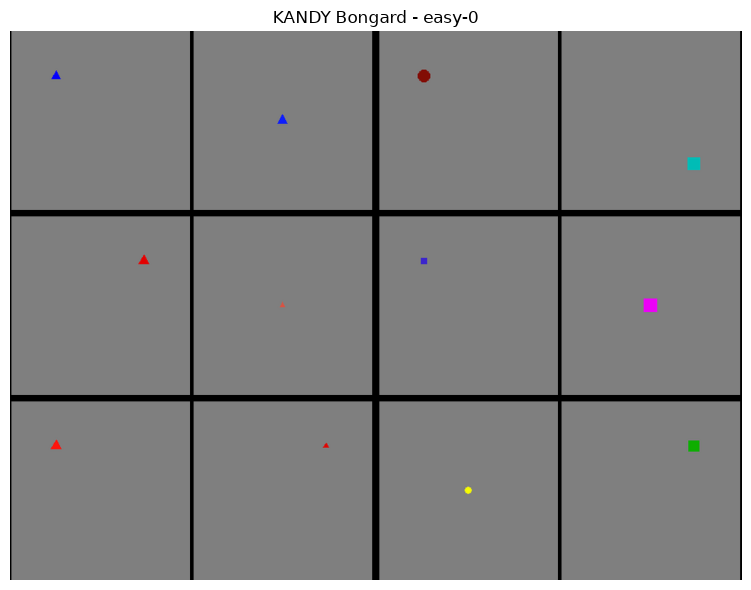

Salvato: docs/images/dataset_examples/kandy_bongard.png


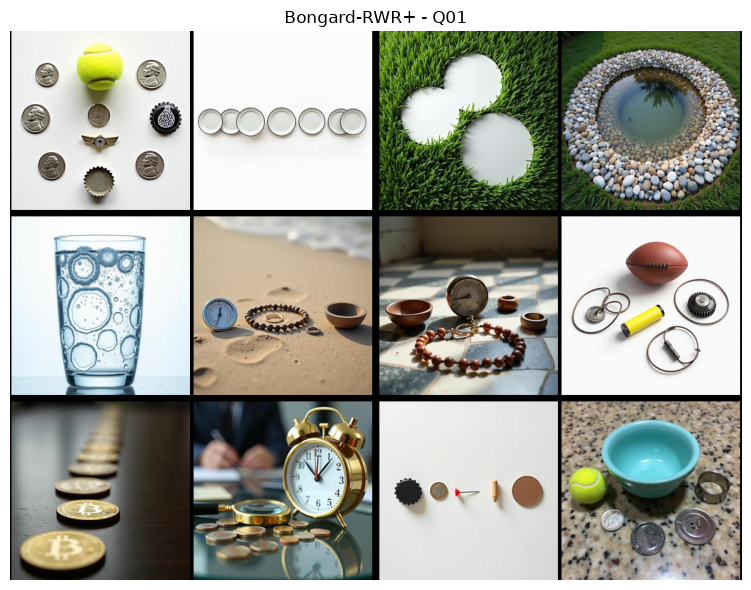

Salvato: docs/images/dataset_examples/rwr_plus.png


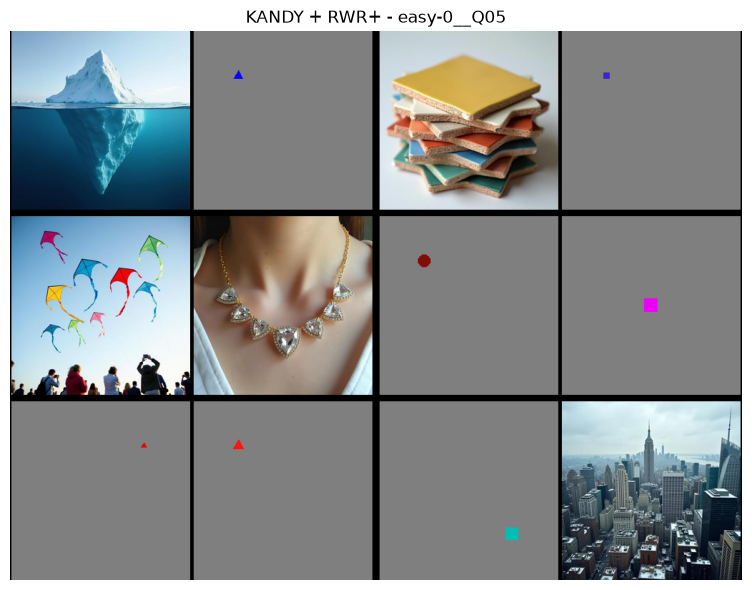

Salvato: docs/images/dataset_examples/kandy_rwr_overlap.png


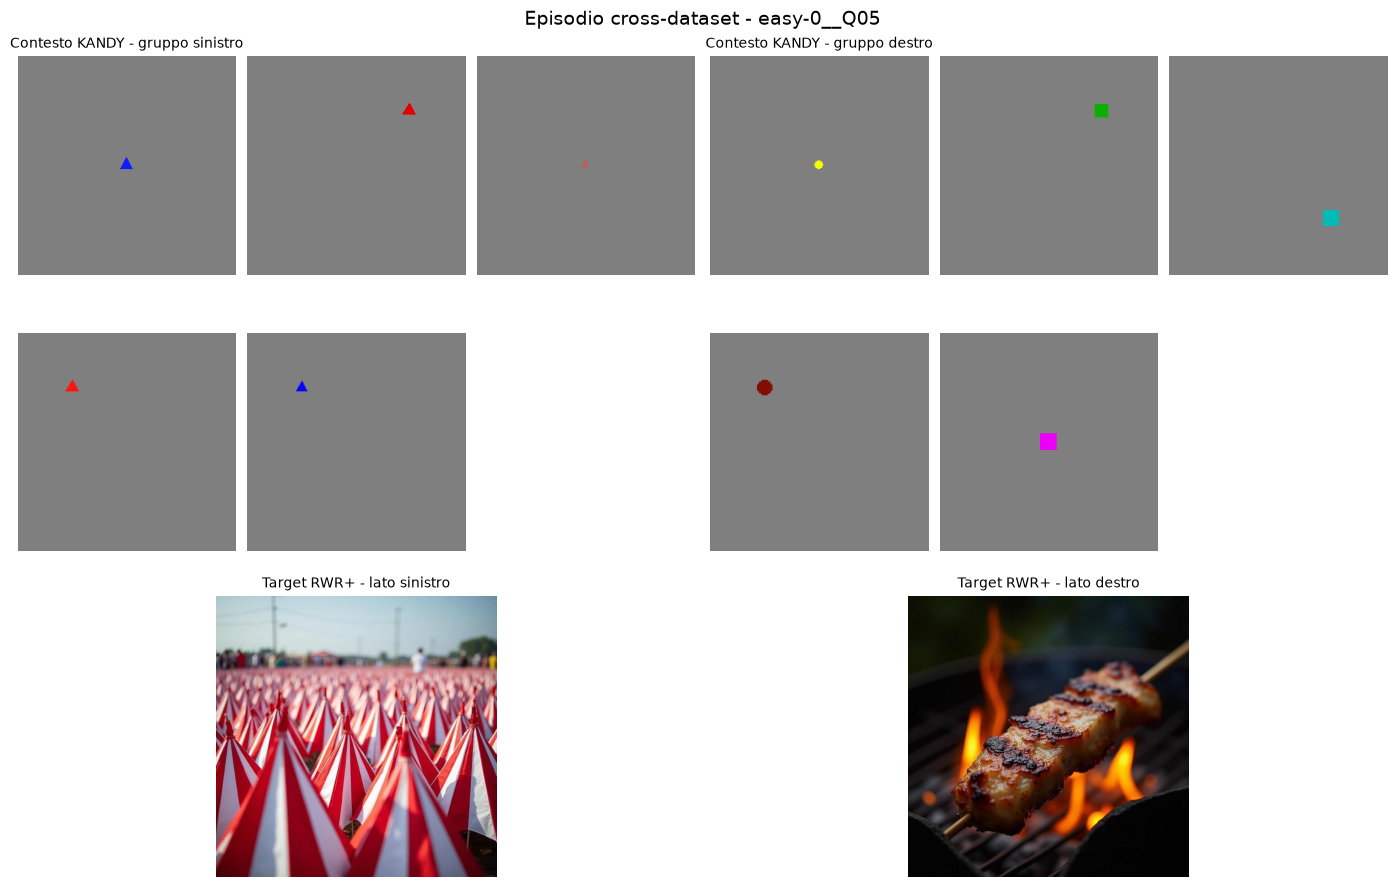

Salvato: docs/images/dataset_examples/cross_dataset.png

Cartella degli esempi: /home/cosimo/progetti/tesi/docs/images/dataset_examples


In [25]:
import matplotlib.pyplot as plt
from math import ceil

#prepariamo una cartella con esempi da inserire nel readme
EXAMPLES_DIR = PROJECT_ROOT / "docs" / "images" / "dataset_examples"
EXAMPLES_DIR.mkdir(parents=True, exist_ok=True)


def show_and_save_example(image_path, title, filename):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Immagine non trovata: {image_path}")

    with Image.open(image_path) as image:
        image = image.convert("RGB")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
    fig.tight_layout()

    output_path = EXAMPLES_DIR / filename
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Salvato: {output_path.relative_to(PROJECT_ROOT)}")


#selezioniamo un esempio per ciascun dataset
kandy_example_row = kandy_manifest.sort_values("problem_id").iloc[0]
rwr_example_row = rwr_manifest.sort_values("profile_id").iloc[0]
mixed_example_row = mixed_manifest.sort_values("problem_id").iloc[0]

kandy_example_path = KANDY_OUTPUT_DIR / kandy_example_row["whole_image"]
rwr_example_path = RWR_OUTPUT_DIR / rwr_example_row["whole_image"]
mixed_example_path = OVERLAP_OUTPUT_DIR / mixed_example_row["whole_image"]

show_and_save_example(
    kandy_example_path,
    f"KANDY Bongard - {kandy_example_row['problem_id']}",
    "kandy_bongard.png"
)

show_and_save_example(
    rwr_example_path,
    f"Bongard-RWR+ - {rwr_example_row['profile_id']}",
    "rwr_plus.png"
)

show_and_save_example(
    mixed_example_path,
    f"KANDY + RWR+ - {mixed_example_row['problem_id']}",
    "kandy_rwr_overlap.png"
)


#prepariamo la visualizzazione di un episodio cross-dataset
cross_problem_id = sorted(cross_test_manifest["problem_id"].unique())[0]
cross_rows = cross_test_manifest[
    cross_test_manifest["problem_id"] == cross_problem_id
].sort_values("target_gold_side")

cross_left = cross_rows[cross_rows["target_gold_side"] == "left"].iloc[0]
cross_right = cross_rows[cross_rows["target_gold_side"] == "right"].iloc[0]

left_context_paths = [
    OVERLAP_OUTPUT_DIR / path
    for path in json.loads(cross_left["left_context_kandy"])
]
right_context_paths = [
    OVERLAP_OUTPUT_DIR / path
    for path in json.loads(cross_left["right_context_kandy"])
]
left_target_path = OVERLAP_OUTPUT_DIR / cross_left["target_image"]
right_target_path = OVERLAP_OUTPUT_DIR / cross_right["target_image"]

fig = plt.figure(figsize=(14, 9))
outer_grid = fig.add_gridspec(2, 2, height_ratios=[2.2, 1.2])


def add_image_group(grid_slot, image_paths, title):
    columns = min(3, max(1, len(image_paths)))
    rows = max(1, ceil(len(image_paths) / columns))
    inner_grid = grid_slot.subgridspec(rows, columns, wspace=0.05, hspace=0.16)

    for index in range(rows * columns):
        ax = fig.add_subplot(inner_grid[index // columns, index % columns])
        ax.axis("off")

        if index == 0:
            ax.set_title(title, fontsize=10)

        if index < len(image_paths):
            with Image.open(image_paths[index]) as image:
                ax.imshow(image.convert("RGB"))


add_image_group(
    outer_grid[0, 0],
    left_context_paths,
    "Contesto KANDY - gruppo sinistro"
)
add_image_group(
    outer_grid[0, 1],
    right_context_paths,
    "Contesto KANDY - gruppo destro"
)
add_image_group(
    outer_grid[1, 0],
    [left_target_path],
    "Target RWR+ - lato sinistro"
)
add_image_group(
    outer_grid[1, 1],
    [right_target_path],
    "Target RWR+ - lato destro"
)

fig.suptitle(f"Episodio cross-dataset - {cross_problem_id}", fontsize=14)
fig.tight_layout()
cross_example_path = EXAMPLES_DIR / "cross_dataset.png"
fig.savefig(cross_example_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Salvato: {cross_example_path.relative_to(PROJECT_ROOT)}")
print(f"\nCartella degli esempi: {EXAMPLES_DIR}")
